# Homework 1

## Setup

In [1]:
from pathlib import Path
import os
import os.path
import glob
import urllib.request
import pystac_client
import planetary_computer as pc
import rasterio as rio
import rasterio
import fiona
import geopandas as gpd
import numpy as np
from shapely.geometry import shape, box, mapping
from matplotlib import pyplot as plt
from rasterio.mask import mask
from rasterio.windows import Window
from rasterio.merge import merge
from rasterio.enums import ColorInterp
from rasterio.features import geometry_mask, geometry_window

In [2]:
project_dir = Path.cwd()
if (project_dir / "ai-urban-sustainability").is_dir():
    project_dir = project_dir / "ai-urban-sustainability"
lab_dir = project_dir / "lab3-raster-data-manipulation"
if project_dir.name == "lab3-raster-data-manipulation":
    lab_dir = project_dir
    project_dir = project_dir.parent

data_dir = lab_dir / "data"
shpfile = data_dir / "city_limit_4326.shp"
naip_dir = lab_dir / "cir-naip"
output_dir = project_dir / "homework1-output-corrected"
output_dir.mkdir(parents=True, exist_ok=True)

tract_file = data_dir / "tl_2010_06075_tract10.shp"
mosaic_file = output_dir / "mosaicked-naip.tif"
masked_file = output_dir / "masked-naip.tif"
city_projected_file = output_dir / "city_limit_proj.shp"
tract_projected_file = output_dir / "san-francisco-tracts-proj.shp"

## 1. Download NAIP imagery

In [3]:
def naip_downloader(shpfile, outfolder, startDate, endDate,
                    skip_existing=True, max_tiles=None):
    os.makedirs(outfolder, exist_ok=True)

    with fiona.open(shpfile) as lyr:
        if lyr.crs.to_string() != 'EPSG:4326':
            raise ValueError(
                f"{shpfile} is in {lyr.crs.to_string()}; STAC needs EPSG:4326. "
                "Reproject it first: gpd.read_file(f).to_crs('EPSG:4326')"
            )
        city_parts = [shape(feat['geometry']) for feat in lyr]
        left, bottom, right, top = lyr.bounds

    area_of_interest = mapping(box(left, bottom, right, top))

    catalog = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1",
        modifier=pc.sign_inplace,
    )
    items_tiles = catalog.search(
        collections=["naip"],
        intersects=area_of_interest,
        datetime=f"{startDate}/{endDate}",
    ).item_collection()

    print(f"{len(items_tiles)} tiles found for {startDate}/{endDate}")

    keep = [it for it in items_tiles
            if any(shape(it.geometry).intersects(part) for part in city_parts)]
    print(f"{len(keep)} of them actually intersect the study area "
          f"({len(items_tiles) - len(keep)} bounding-box-only tiles skipped)")

    if max_tiles:
        keep = keep[:max_tiles]

    downloaded = []
    for n, item in enumerate(keep, start=1):
        outfilename = os.path.join(outfolder, item.id + ".tif")

        if skip_existing and os.path.exists(outfilename):
            print(f"[{n}/{len(keep)}] {item.id} -- already on disk")
            downloaded.append(outfilename)
            continue

        print(f"[{n}/{len(keep)}] downloading {item.id} ...")
        urllib.request.urlretrieve(item.assets["image"].href, outfilename)
        downloaded.append(outfilename)

    print(f"\n{len(downloaded)} tiles available in '{outfolder}'")
    return downloaded

In [4]:
shapefile  = str(shpfile)
cir_naips  = str(naip_dir)
startDate  = '2018-06-01'
endDate    = '2018-09-30'

tiles = naip_downloader(shapefile, cir_naips, startDate, endDate)

22 tiles found for 2018-06-01/2018-09-30
17 of them actually intersect the study area (5 bounding-box-only tiles skipped)
[1/17] ca_m_3712221_nw_10_060_20180804_20190210 -- already on disk
[2/17] ca_m_3712221_ne_10_060_20180804_20190210 -- already on disk
[3/17] ca_m_3712220_ne_10_060_20180804_20190210 -- already on disk
[4/17] ca_m_3712213_sw_10_060_20180804_20190209 -- already on disk
[5/17] ca_m_3712213_se_10_060_20180804_20190209 -- already on disk
[6/17] ca_m_3712213_nw_10_060_20180804_20190209 -- already on disk
[7/17] ca_m_3712213_ne_10_060_20180804_20190209 -- already on disk
[8/17] ca_m_3712212_se_10_060_20180804_20190209 -- already on disk
[9/17] ca_m_3712212_nw_10_060_20180804_20190210 -- already on disk
[10/17] ca_m_3712212_ne_10_060_20180804_20190210 -- already on disk
[11/17] ca_m_3712222_nw_10_060_20180723_20190209 -- already on disk
[12/17] ca_m_3712222_ne_10_060_20180723_20190210 -- already on disk
[13/17] ca_m_3712214_sw_10_060_20180723_20190209 -- already on disk
[14

## 2. Raster data manipulation

In [5]:
naip_file = tiles[0]
naip_dataset = rio.open(naip_file)
naip_bounds = naip_dataset.bounds
naip_bounds

BoundingBox(left=543894.0, bottom=4171110.0, right=549750.0, top=4178382.0)

In [6]:
naip_dataset.meta

{'driver': 'GTiff',
 'dtype': 'uint8',
 'nodata': None,
 'width': 9760,
 'height': 12120,
 'count': 4,
 'crs': CRS.from_wkt('PROJCS["NAD83 / UTM zone 10N",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-123],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","26910"]]'),
 'transform': Affine(0.6, 0.0, 543894.0,
        0.0, -0.6, 4178382.0)}

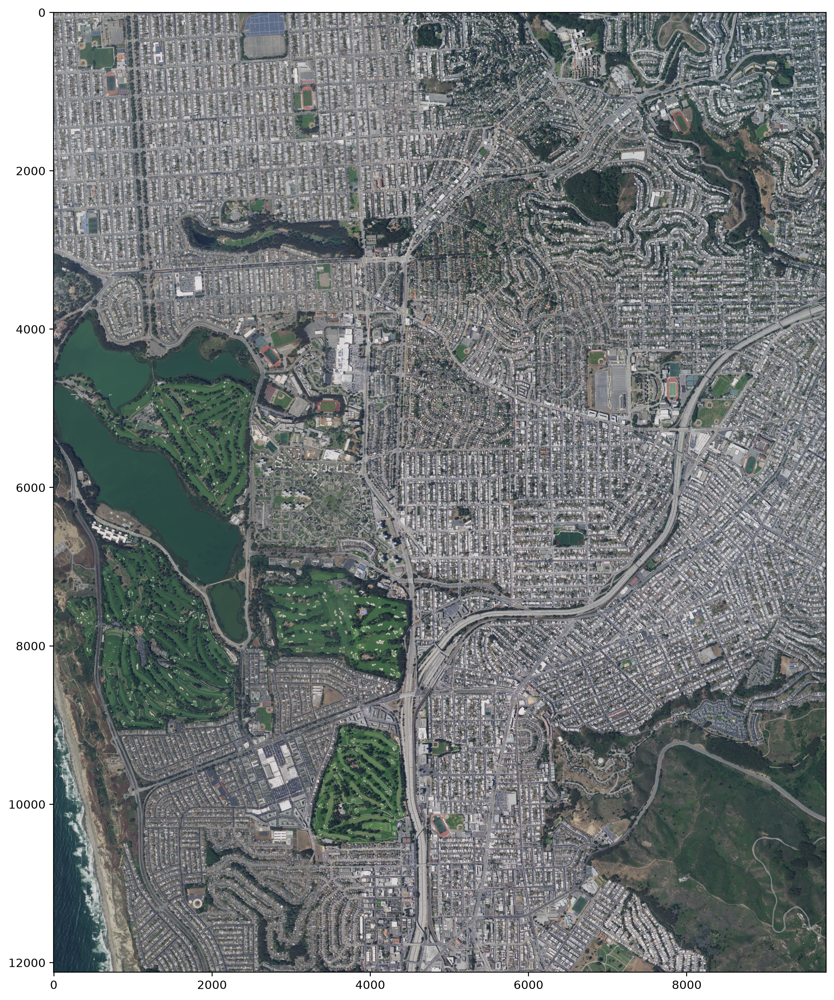

In [7]:
nir = np.float32(naip_dataset.read(4, masked=True))
blue = np.float32(naip_dataset.read(3))
green = np.float32(naip_dataset.read(2))
red = np.float32(naip_dataset.read(1, masked=True))

cir = np.dstack((red,green,blue))

plt.figure(figsize=(15, 15), dpi=200)
plt.imshow(cir.astype(np.uint8))

Resampling to 6060,4880


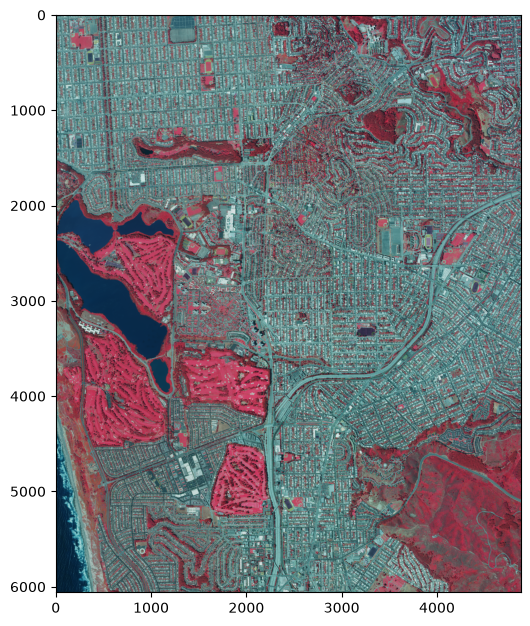

In [8]:
def display_naip_tile(filename, dsfactor = 2):

    with rio.open(filename) as raster:

        h = int(raster.height/dsfactor)
        w = int(raster.width/dsfactor)
        print('Resampling to {},{}'.format(h,w))
        ir = raster.read(4, out_shape=(1, h, w))
        r = raster.read(1, out_shape=(1, h, w))
        g = raster.read(2, out_shape=(1, h, w))

    cir = np.dstack((ir,r,g))
    fig = plt.figure(figsize=(7.5, 7.5), dpi=100, edgecolor='k')
    plt.imshow(cir)
    raster.close()

display_naip_tile(naip_file)

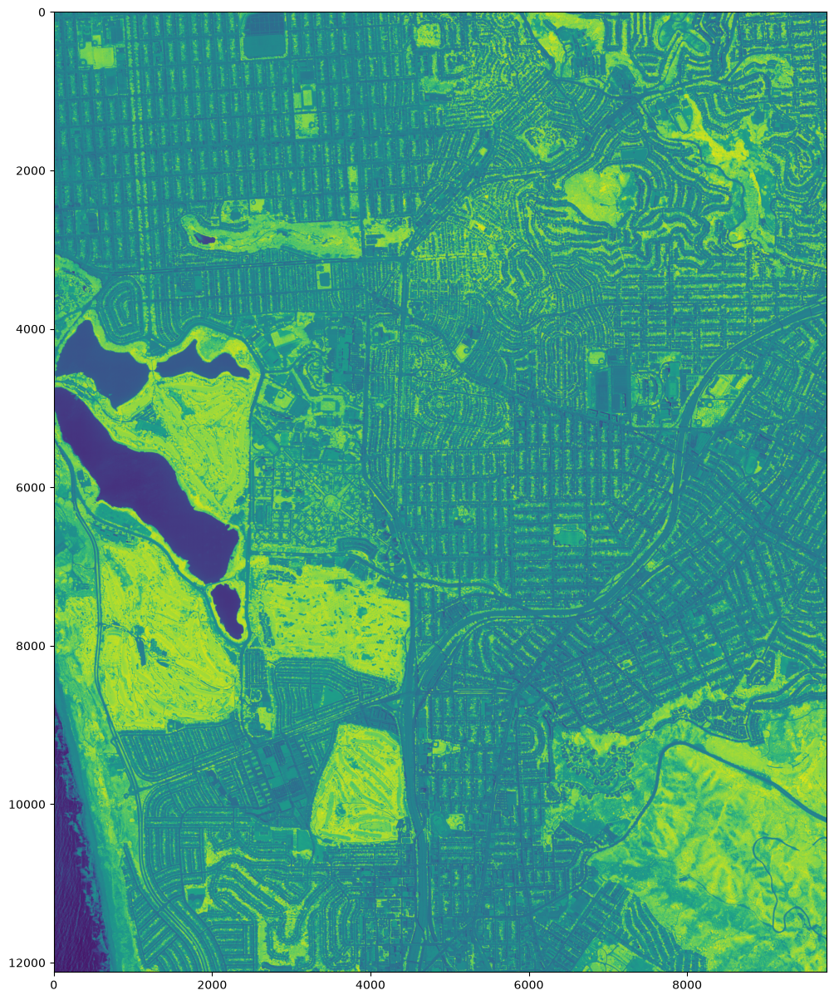

In [9]:
denominator = nir + red
ndvi = np.ma.masked_invalid(
    np.ma.divide(nir - red, np.ma.masked_equal(denominator, 0))
)

plt.figure(figsize=(15, 15))
plt.imshow(ndvi)

In [10]:
ndvi.max()

np.float32(0.7419355)

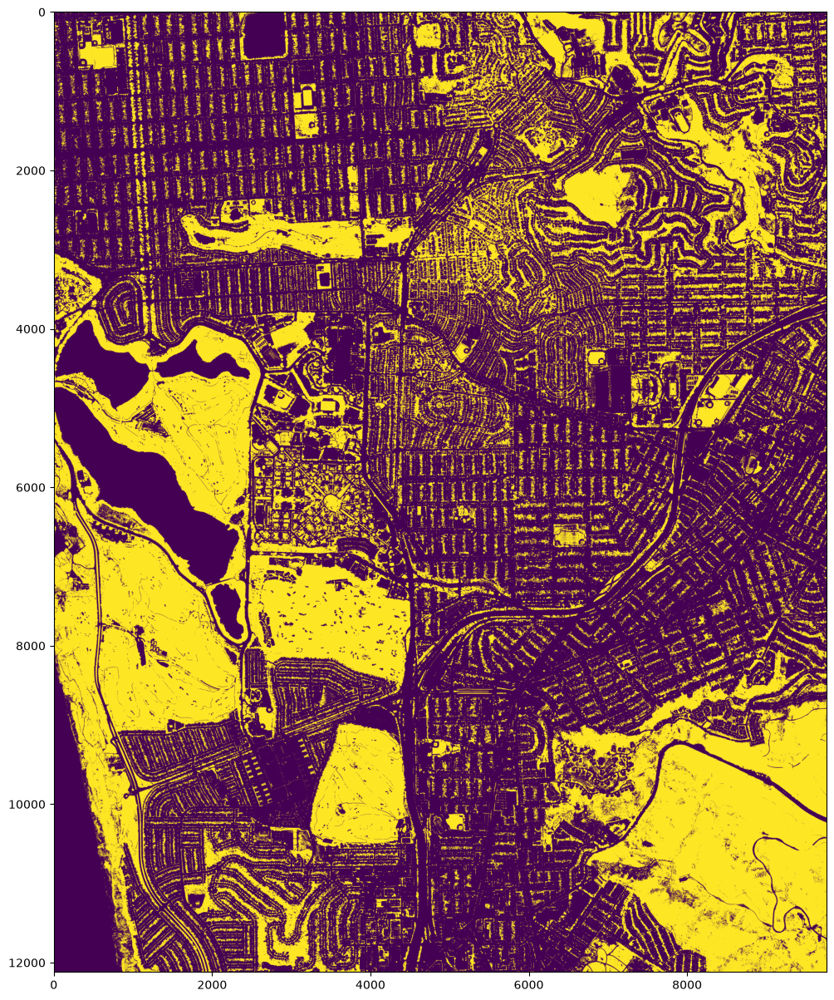

In [11]:
plt.figure(figsize=(15, 15))
veg = np.ma.array((ndvi > 0).astype(np.uint8), mask=np.ma.getmaskarray(ndvi))
plt.imshow(veg)

In [12]:
out_tif = str(output_dir / "single-tile-vegetation.tif")

out_meta = naip_dataset.meta.copy()

In [13]:
out_meta

{'driver': 'GTiff',
 'dtype': 'uint8',
 'nodata': None,
 'width': 9760,
 'height': 12120,
 'count': 4,
 'crs': CRS.from_wkt('PROJCS["NAD83 / UTM zone 10N",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-123],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","26910"]]'),
 'transform': Affine(0.6, 0.0, 543894.0,
        0.0, -0.6, 4178382.0)}

In [14]:
veg.shape

(12120, 9760)

In [15]:
out_meta.update({'count': 1, 'dtype': 'uint8', 'nodata': 255,
                 'compress': 'lzw'})
veg = veg.reshape(1, veg.shape[0], veg.shape[1])

In [16]:
with rio.open(out_tif, "w", **out_meta) as dest:
    dest.write(veg.filled(255))

## 3. Mosaic imagery

In [17]:
outfile = str(mosaic_file)
tiflist = list(tiles)
src_files_to_mosaic = []
try:
    for fp in tiflist:
        src_files_to_mosaic.append(rasterio.open(fp))
    print('The number of mosaicked tiles is:', len(src_files_to_mosaic))
    # 256 is outside the original 0–255 values, so valid zeros remain valid.
    merge(src_files_to_mosaic, dst_path=outfile, dtype='uint16', nodata=256,
          mem_limit=256, dst_kwds={'compress': 'lzw', 'BIGTIFF': 'YES',
                                  'photometric': 'RGB', 'ALPHA': 'UNSPECIFIED'})
    with rasterio.open(outfile, 'r+') as dest:
        dest.colorinterp = (ColorInterp.red, ColorInterp.green,
                            ColorInterp.blue, ColorInterp.undefined)
        dest.descriptions = ('Red', 'Green', 'Blue', 'Near infrared')
finally:
    for tile_src in src_files_to_mosaic:
        tile_src.close()
print('Mosaic saved:', outfile)

The number of mosaicked tiles is: 17


Mosaic saved: /Users/freddie/Projects/HailMary/ai-urban-sustainability/homework1-output-corrected/mosaicked-naip.tif


## 4. Project boundaries and mask imagery

In [18]:
with rio.open(mosaic_file) as src:
    raster_crs = src.crs

gpd.read_file(shpfile).to_crs(raster_crs).to_file(city_projected_file)
gpd.read_file(tract_file).to_crs(raster_crs).to_file(tract_projected_file)

In [19]:
input_value_raster = str(mosaic_file)
projected_shpfile = str(city_projected_file)
out_raster = str(masked_file)

with fiona.open(projected_shpfile, "r") as shapefile:
    shapes = [feature["geometry"] for feature in shapefile]

with rasterio.open(input_value_raster) as src:
    crop_window = geometry_window(src, shapes)
    height, width = int(crop_window.height), int(crop_window.width)
    out_meta = src.meta.copy()
    out_meta.update({"driver": "GTiff", "height": height, "width": width,
                     "transform": src.window_transform(crop_window),
                     "dtype": "uint8", "nodata": None, "compress": "lzw",
                     "BIGTIFF": "YES", "photometric": "RGB", "ALPHA": "UNSPECIFIED"})
    with rasterio.open(out_raster, "w", **out_meta) as dest:
        dest.colorinterp = src.colorinterp
        dest.descriptions = src.descriptions
        for row in range(0, height, 2000):
            for col in range(0, width, 2000):
                window = Window(col, row, min(2000, width - col), min(2000, height - row))
                source_window = Window(crop_window.col_off + col, crop_window.row_off + row,
                                       window.width, window.height)
                data = src.read(window=source_window, masked=True)
                inside_city = geometry_mask(
                    shapes, out_shape=data.shape[1:],
                    transform=src.window_transform(source_window), invert=True
                )
                valid = inside_city & ~np.ma.getmaskarray(data).any(axis=0)
                values = data.filled(0).astype('uint8')
                values[:, ~valid] = 0
                dest.write(values, window=window)
                dest.write_mask(valid, window=window)
            print('City rows clipped:', min(row + 2000, height), '/', height)
print('City mask saved:', out_raster)

City rows clipped: 2000 / 41056


City rows clipped: 4000 / 41056


City rows clipped: 6000 / 41056


City rows clipped: 8000 / 41056


City rows clipped: 10000 / 41056


...

City rows clipped: 34000 / 41056


City rows clipped: 36000 / 41056


City rows clipped: 38000 / 41056


City rows clipped: 40000 / 41056


City rows clipped: 41056 / 41056
City mask saved: /Users/freddie/Projects/HailMary/ai-urban-sustainability/homework1-output-corrected/masked-naip.tif


## 5. Split imagery into tiles

In [20]:
outfolder = str(output_dir / "naip-tiles")
os.makedirs(outfolder, exist_ok=True)
split_tiles = []
with rasterio.open(str(masked_file)) as lu_dataset:
    height, width = lu_dataset.shape
    tile_width = 2000
    tile_height = 2000
    tile_num_col = (width + tile_width - 1) // tile_width
    tile_num_row = (height + tile_height - 1) // tile_height

    for i in range(tile_num_row):
        for j in range(tile_num_col):
            tilename = os.path.join(outfolder, 'row%s-col%s.tif' % (i, j))
            row_start = i * tile_height
            col_start = j * tile_width
            window = Window(col_off=col_start, row_off=row_start,
                            width=min(tile_width, width - col_start),
                            height=min(tile_height, height - row_start))
            kwargs = lu_dataset.meta.copy()
            kwargs.update({'height': int(window.height), 'width': int(window.width),
                           'transform': lu_dataset.window_transform(window),
                           'photometric': 'RGB', 'ALPHA': 'UNSPECIFIED'})
            with rasterio.open(tilename, 'w', **kwargs) as dst:
                dst.write(lu_dataset.read(window=window))
                dst.write_mask(lu_dataset.dataset_mask(window=window))
                dst.colorinterp = lu_dataset.colorinterp
                dst.descriptions = lu_dataset.descriptions
            split_tiles.append(tilename)
print('Tiles written:', len(split_tiles))

Tiles written: 525


## 6. Vegetation cover

In [21]:
outfolder = str(output_dir / "veg-tiles")
os.makedirs(outfolder, exist_ok=True)

for tiffile in split_tiles:
    with rio.open(tiffile) as naip_dataset:
        red = np.float32(naip_dataset.read(1, masked=True))
        nir = np.float32(naip_dataset.read(4, masked=True))
        out_meta = naip_dataset.meta.copy()

    denominator = nir + red
    ndvi = np.ma.masked_invalid(
        np.ma.divide(nir - red, np.ma.masked_equal(denominator, 0))
    )
    veg = np.ma.array((ndvi > 0).astype(np.uint8), mask=np.ma.getmaskarray(ndvi))
    out_meta.update({'count': 1, 'dtype': 'uint8', 'nodata': 255,
                     'compress': 'lzw'})
    out_tif = os.path.join(outfolder, os.path.basename(tiffile))
    with rio.open(out_tif, "w", **out_meta) as dest:
        dest.write(veg.filled(255), 1)
print('Vegetation tiles written:', len(split_tiles))

Vegetation tiles written: 525


## 7. Zonal statistics

In [22]:
inraster = str(masked_file)
input_zone_polygon = str(tract_projected_file)
output_shp_res = str(output_dir / "vegCoverCensus-tract.shp")

with rasterio.open(inraster) as naip_dataset, fiona.open(input_zone_polygon) as lyr:
    schema = lyr.schema.copy()
    schema['properties'] = dict(schema['properties'])
    schema['properties']['ndvi'] = 'float'
    schema['properties']['valid_px'] = 'int64'

    with fiona.open(output_shp_res, 'w', driver="ESRI Shapefile",
                    crs=lyr.crs, schema=schema) as output:
        for idx, feat in enumerate(lyr):
            props = dict(feat['properties'])
            geom = feat['geometry']
            zone_shapes = [geom]
            try:
                outNAIP_image, out_transform = rasterio.mask.mask(
                    naip_dataset, zone_shapes, crop=True, filled=False
                )
            except ValueError:
                props['ndvi'] = None
                props['valid_px'] = 0
                output.write({'properties': props, 'geometry': geom})
                continue

            nir = np.float32(outNAIP_image[3, :, :])
            red = np.float32(outNAIP_image[0, :, :])
            denominator = nir + red
            ndvi = np.ma.masked_invalid(
                np.ma.divide(nir - red, np.ma.masked_equal(denominator, 0))
            )
            valid_count = int(ndvi.count())
            mean_val = float(ndvi.mean(dtype='float64')) if valid_count else None
            props['ndvi'] = mean_val
            props['valid_px'] = valid_count
            output.write({'properties': props, 'geometry': geom})
            if (idx + 1) % 25 == 0:
                print('Tracts processed:', idx + 1)
print('Zonal statistics saved:', output_shp_res)

Tracts processed: 25


Tracts processed: 50


Tracts processed: 75


Tracts processed: 100


Tracts processed: 125


Tracts processed: 150


Tracts processed: 175


Zonal statistics saved: /Users/freddie/Projects/HailMary/ai-urban-sustainability/homework1-output-corrected/vegCoverCensus-tract.shp


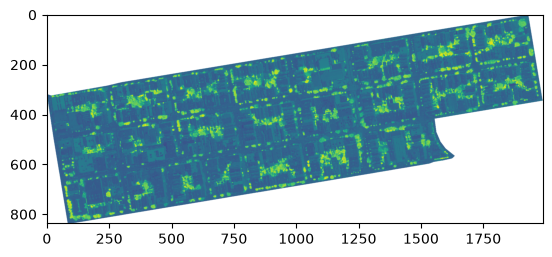

In [23]:
plt.imshow(nir - red)

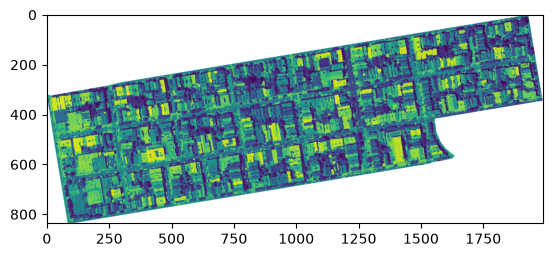

In [24]:
plt.imshow(outNAIP_image[0,:,:])

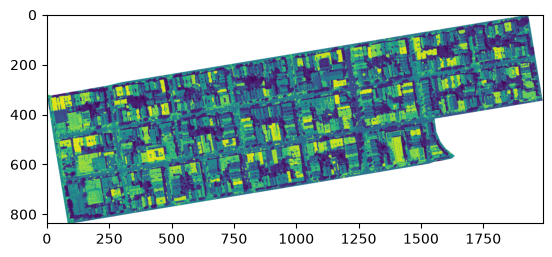

In [25]:
plt.imshow(outNAIP_image[2,:,:])